<a href="https://colab.research.google.com/github/lakshuu-jay/Projects/blob/main/UnderfittingVsOverfitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

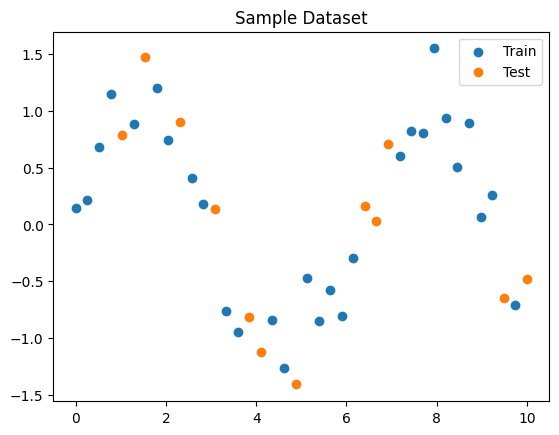

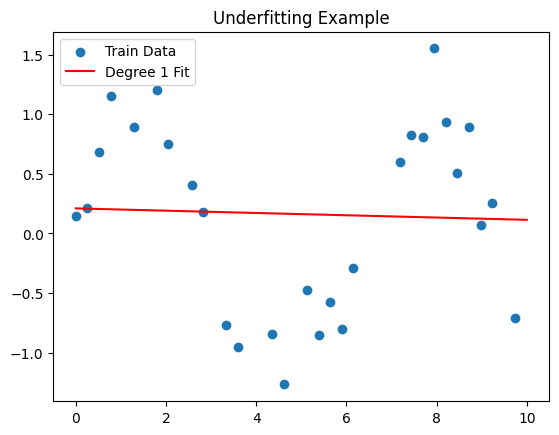

Train MSE: 0.5905273988271039
Test MSE: 0.7420347855960245


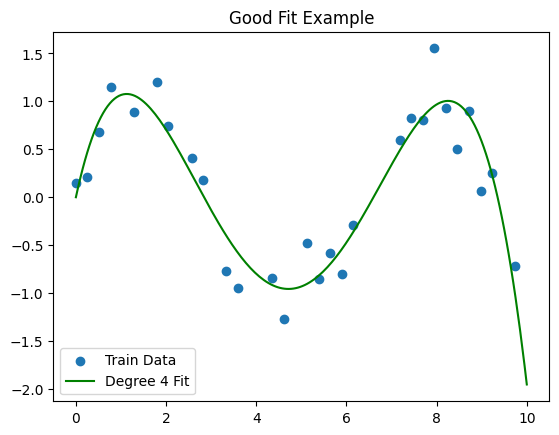

Train MSE: 0.07198819429451138
Test MSE: 0.291600185301028


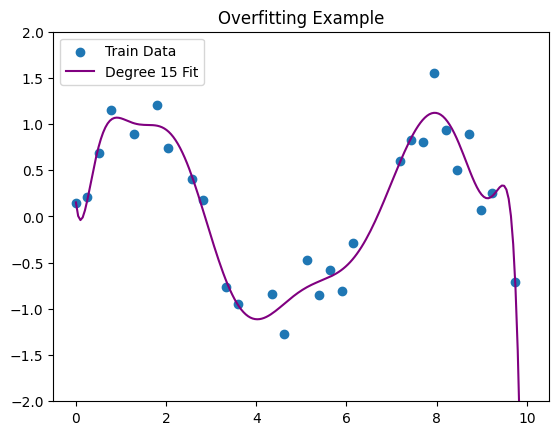

Train MSE: 0.035912205441249664
Test MSE: 4.747314041885745


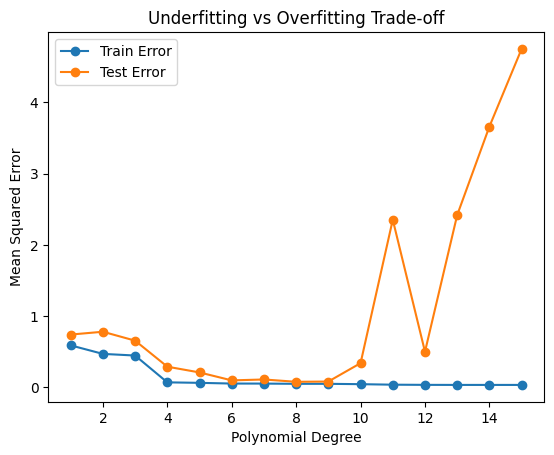

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.polynomial import Polynomial
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)
X = np.linspace(0, 10, 40)
y = np.sin(X) + np.random.normal(0, 0.3, size=X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, label="Test")
plt.legend()
plt.title("Sample Dataset")
plt.show()

p1 = Polynomial.fit(X_train, y_train, deg=1)
x_line = np.linspace(0, 10, 200)

plt.scatter(X_train, y_train, label="Train Data")
plt.plot(x_line, p1(x_line), color="red", label="Degree 1 Fit")
plt.legend()
plt.title("Underfitting Example")
plt.show()

print("Train MSE:", mean_squared_error(y_train, p1(X_train)))
print("Test MSE:", mean_squared_error(y_test, p1(X_test)))

p2 = Polynomial.fit(X_train, y_train, deg=4)

plt.scatter(X_train, y_train, label="Train Data")
plt.plot(x_line, p2(x_line), color="green", label="Degree 4 Fit")
plt.legend()
plt.title("Good Fit Example")
plt.show()

print("Train MSE:", mean_squared_error(y_train, p2(X_train)))
print("Test MSE:", mean_squared_error(y_test, p2(X_test)))

p3 = Polynomial.fit(X_train, y_train, deg=15)

plt.scatter(X_train, y_train, label="Train Data")
plt.plot(x_line, p3(x_line), color="purple", label="Degree 15 Fit")
plt.ylim(-2, 2)
plt.legend()
plt.title("Overfitting Example")
plt.show()

print("Train MSE:", mean_squared_error(y_train, p3(X_train)))
print("Test MSE:", mean_squared_error(y_test, p3(X_test)))

degrees = range(1, 16)
train_errors = []
test_errors = []

for d in degrees:
    p = Polynomial.fit(X_train, y_train, deg=d)
    train_errors.append(mean_squared_error(y_train, p(X_train)))
    test_errors.append(mean_squared_error(y_test, p(X_test)))

plt.plot(degrees, train_errors, marker="o", label="Train Error")
plt.plot(degrees, test_errors, marker="o", label="Test Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Underfitting vs Overfitting Trade-off")
plt.legend()
plt.show()